In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
FIG, TAB, PRED = ROOT/"results"/"figures", ROOT/"results"/"tables", ROOT/"results"/"predictions"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
def savefig(name):
    plt.savefig(FIG/f"{name}.png", bbox_inches="tight"); print("saved ->", f"results/figures/{name}.png")
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")

# 12 · Structured lag models: can a parsimonious lag structure recover forecasting skill?

Notebooks 07-09 showed that 16 *free* weekly lags are statistically wasteful. The panel analysis (notebook 10) suggested structure: a smooth profile over weeks, phenological stages and an asymmetric (drought-dominated) response.
`scripts/22_run_structured_lag_models.py` therefore tested **eight pre-specified candidates** (never modified after seeing results), all in the anomaly formulation (tier C):

| Code | Representation (+ state FE, `IMD_Tmax`) | Parameters |
|---|---|---|
| F8 (ref) | seasonal total anomaly | 1 |
| S1 / S2 | smooth distributed lag: Legendre basis of degree 2 / 3 over the 16 weeks | 3 / 4 |
| S3 | 5 stage-sum anomalies | 5 |
| S4 | total anomaly split into deficit and surplus | 2 |
| S5 / S6 | train-only learned panel-FE weather index (and its deficit/surplus split) | 1 / 2 |
| S7 | stage sums + deficit/surplus | 7 |

Rules fixed beforehand: selection per model on **validation MAE only**; test years scored once; Holm correction over the 21 (7 candidates × 3 models) paired comparisons against F8.

In [2]:
from src.experiment import *
M = pd.read_csv(TAB/"p2_structured_lag_metrics.csv"); SEL = pd.read_csv(TAB/"p2_structured_lag_selection.csv"); B = pd.read_csv(TAB/"p2_structured_lag_bootstrap.csv")
RB = pd.read_csv(TAB/"p2_structured_rolling_bootstrap.csv"); RY = pd.read_csv(TAB/"p2_structured_rolling_by_year.csv")
main = pd.read_csv(TAB/"p2_main_summary_test.csv"); D = pd.read_csv(ROOT/"data/processed/phase2_lag_features.csv.gz"); parts = split_frame(D)
base = np.abs(parts["test"][TARGET] - parts["test"][BASE_COL]).mean()
T = M[M.split == "test"].groupby(["feature_set", "model"]).MAE.agg(["mean", "std"]).reset_index()
V = M[M.split == "validation"].groupby(["feature_set", "model"]).MAE.mean().unstack().round(1); print("VALIDATION MAE (selection data):"); V

VALIDATION MAE (selection data):


model,RF,Ridge,XGB
feature_set,,,
F8_Total_Anomaly (reference),340.300,346.800,345.000
S1_Smooth2,339.100,347.500,344.900
S2_Smooth3,339.400,347.300,347.500
S3_StageAnomaly,341.800,349.100,351.200
S4_AsymTotal,340.400,346.000,344.800
S5_PanelIndex,341.400,346.000,345.500
S6_PanelIndexAsym,341.000,345.400,344.900
S7_StageAnomaly+Asym,341.300,348.100,349.400


In [3]:
t = T.pivot(index="feature_set", columns="model", values="mean")
f5 = main[(main.tier == "C_anomaly") & (main.feature_set == "F5_Lag16")].set_index("model").MAE
t.loc["F5 16 free lags (notebook 07)"] = f5; t = t.sort_values("RF"); print("TEST MAE, kg/ha (5 seeds); no-weather baseline = %.1f" % base); t.round(1)

TEST MAE, kg/ha (5 seeds); no-weather baseline = 337.2


model,RF,Ridge,XGB
feature_set,,,
S2_Smooth3,326.500,330.100,330.200
S1_Smooth2,327.000,330.700,330.000
S7_StageAnomaly+Asym,327.900,329.600,331.200
S3_StageAnomaly,328.200,330.400,333.900
F8_Total_Anomaly (reference),329.000,331.100,333.700
S4_AsymTotal,329.100,330.400,334.100
S5_PanelIndex,330.900,333.300,335.400
S6_PanelIndexAsym,331.500,332.500,335.200
F5 16 free lags (notebook 07),332.700,334.300,338.100


saved -> results/figures/p2_12_structured_lags.png


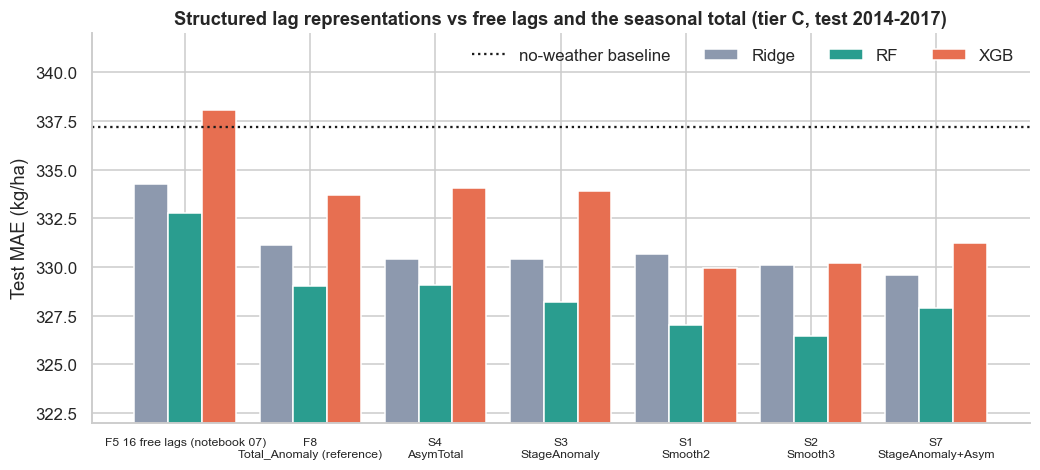

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.6)); order = ["F5 16 free lags (notebook 07)", "F8_Total_Anomaly (reference)", "S4_AsymTotal", "S3_StageAnomaly", "S1_Smooth2", "S2_Smooth3", "S7_StageAnomaly+Asym"]
pal = {"Ridge": "#8d99ae", "RF": "#2a9d8f", "XGB": "#e76f51"}
for k, mod in enumerate(["Ridge", "RF", "XGB"]):
    ax.bar(np.arange(len(order)) + (k - 1) * .27, t.loc[order, mod], .27, color=pal[mod], label=mod)
ax.axhline(base, color="k", ls=":", label="no-weather baseline"); ax.set_ylim(322, 342); ax.set_xticks(range(len(order)))
ax.set_xticklabels([o.replace("_", "\n", 1) for o in order], fontsize=8); ax.set_ylabel("Test MAE (kg/ha)"); ax.legend(frameon=False, ncol=4)
ax.set_title("Structured lag representations vs free lags and the seasonal total (tier C, test 2014-2017)"); savefig("p2_12_structured_lags"); plt.show()

## Validation-based selection and paired tests against the seasonal total

In [5]:
print("Candidate chosen per model on VALIDATION MAE:"); display(SEL.round(2)) if False else None
SEL.round(2)

Candidate chosen per model on VALIDATION MAE:


,feature_set,model,val_MAE,ref_val_MAE,test_MAE
0,S1_Smooth2,RF,339.150,340.310,327.040
1,S6_PanelIndexAsym,Ridge,345.440,346.760,332.510
2,S4_AsymTotal,XGB,344.790,344.970,334.050


In [6]:
B["significant_after_Holm"] = B.p_holm < .05
B.round(3)

,model,candidate,delta_mae,ci_lo,ci_hi,p_boot,p_holm,significant_after_Holm
0,Ridge,S2_Smooth3,-1.038,-1.505,-0.561,0.000,0.000,True
1,Ridge,S5_PanelIndex,2.146,1.151,3.134,0.000,0.000,True
2,RF,S2_Smooth3,-2.559,-4.486,-0.689,0.008,0.152,False
3,XGB,S1_Smooth2,-4.087,-7.203,-1.132,0.008,0.153,False
4,Ridge,S1_Smooth2,-0.485,-0.850,-0.123,0.010,0.170,False
5,RF,S1_Smooth2,-1.976,-3.641,-0.364,0.013,0.208,False
6,XGB,S2_Smooth3,-3.853,-7.732,-0.123,0.042,0.622,False
7,RF,S6_PanelIndexAsym,2.443,-0.297,5.002,0.077,1.000,False
8,Ridge,S6_PanelIndexAsym,1.370,-0.426,3.201,0.133,1.000,False
9,Ridge,S3_StageAnomaly,-0.712,-1.645,0.248,0.140,1.000,False


## Robustness: rolling-origin one-year-ahead forecasts 2011-2017 (hyper-parameters fixed)

model  candidate  delta_mae  ci_lo  ci_hi  p_boot
   RF S1_Smooth2     -1.131 -2.370  0.158   0.078
   RF S2_Smooth3     -1.046 -2.551  0.527   0.194
   RF   F5_Lag16      3.569  0.856  6.237   0.014
  XGB S1_Smooth2     -0.807 -3.091  1.464   0.489
  XGB S2_Smooth3      0.570 -2.309  3.405   0.688
  XGB   F5_Lag16      5.854  1.174 10.147   0.017


saved -> results/figures/p2_12_structured_rolling.png


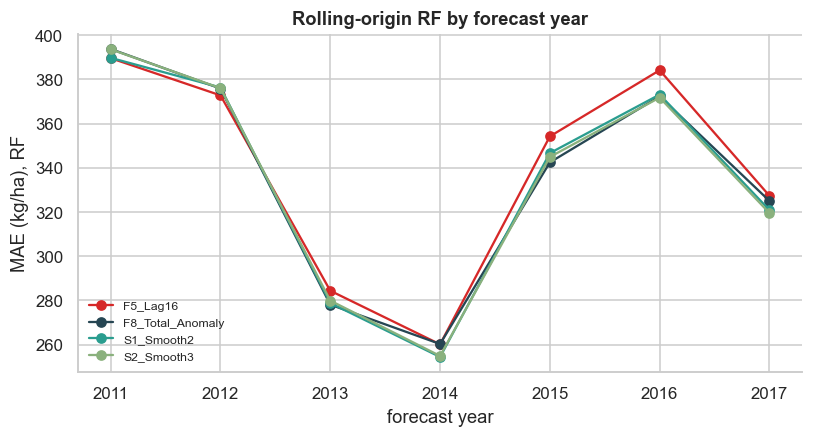

In [7]:
print(RB.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(8.5, 4)); 
for fs, c in [("F5_Lag16", "#d62828"), ("F8_Total_Anomaly", "#264653"), ("S1_Smooth2", "#2a9d8f"), ("S2_Smooth3", "#8ab17d")]:
    q = RY[(RY.model == "RF") & (RY.feature_set == fs)]; ax.plot(q.test_year, q.ae, marker="o", color=c, label=fs)
ax.set_xlabel("forecast year"); ax.set_ylabel("MAE (kg/ha), RF"); ax.legend(frameon=False, fontsize=8); ax.set_title("Rolling-origin RF by forecast year")
savefig("p2_12_structured_rolling"); plt.show()

### Reading
* **Structure rescues the lags.** Smooth lag profiles (3-4 parameters) are 5-6 kg/ha (RF) and 8 kg/ha (XGB) better than 16 free lags, and they match or slightly beat the seasonal total in all three model families.
* **The gain over the total is small** (≈ 0.6 % on the main split, −2.0 to −4.1 kg/ha for RF/XGB), consistent in sign across smooth variants and models, but only the Ridge/degree-3 comparison survives Holm correction, and under rolling origin RF is −1.1 [-2.4,+0.2] and XGB is null.
  We therefore describe it as *consistent but modest*, not as a decisive improvement.
* **Learned index and asymmetric split do not help** here; stage sums help only marginally.